In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/selva86/datasets/master/supermarket_sales.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Rows: 1000
Columns: 17


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  

In [ ]:
df.describe()

,Unit price,Quantity,Tax 5%,Total,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000


In [ ]:
# Check for missing values

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64


In [ ]:
# Check for duplicate records

duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


In [ ]:
# Remove duplicate records

before_cleaning = len(df)

df = df.drop_duplicates()

after_cleaning = len(df)

print("Records before cleaning:", before_cleaning)
print("Records after cleaning:", after_cleaning)
print("Duplicate records removed:", before_cleaning - after_cleaning)

Records before cleaning: 1000
Records after cleaning: 1000
Duplicate records removed: 0


In [ ]:
# Convert Date column to datetime format

df["Date"] = pd.to_datetime(df["Date"])

print("Date column converted successfully!")
print(df["Date"].dtype)

Date column converted successfully!
datetime64[ns]


In [ ]:
# Extract useful information from Date

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["Month_Name"] = df["Date"].dt.strftime("%B")

print("Date preprocessing completed!")

Date preprocessing completed!


In [ ]:
# Display the new date-related columns

df[["Date", "Year", "Month", "Month_Name", "Day"]].head()

,Date,Year,Month,Month_Name,Day
0,2019-01-05,2019,1,January,5
1,2019-03-08,2019,3,March,8
2,2019-03-03,2019,3,March,3
3,2019-01-27,2019,1,January,27
4,2019-02-08,2019,2,February,8


In [ ]:
# Final data quality check

print("===== DATA QUALITY CHECK =====")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("Total Duplicate Rows:", df.duplicated().sum())

===== DATA QUALITY CHECK =====
Total Rows: 1000
Total Columns: 21

Total Missing Values: 0
Total Duplicate Rows: 0


In [1]:
# ==========================================
# KEY PERFORMANCE INDICATORS (KPIs)
# ==========================================

total_revenue = df["Total"].sum()
total_transactions = df["Invoice ID"].nunique()
total_quantity = df["Quantity"].sum()
average_sale = df["Total"].mean()
average_rating = df["Rating"].mean()
total_gross_income = df["gross income"].sum()

print("=" * 55)
print("           SUPERMARKET SALES KPI SUMMARY")
print("=" * 55)

print(f"Total Revenue       : ${total_revenue:,.2f}")
print(f"Total Transactions  : {total_transactions:,}")
print(f"Total Quantity Sold : {total_quantity:,}")
print(f"Average Sale        : ${average_sale:,.2f}")
print(f"Average Rating      : {average_rating:.2f} / 10")
print(f"Total Gross Income  : ${total_gross_income:,.2f}")

print("=" * 55)

NameError: name 'df' is not defined

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/selva86/datasets/master/supermarket_sales.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print(df.shape)

(1000, 17)


In [5]:
# Convert Date column to datetime

df["Date"] = pd.to_datetime(df["Date"])

# Extract useful date information

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["Month_Name"] = df["Date"].dt.strftime("%B")

print("Date preprocessing completed!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Date preprocessing completed!
Rows: 1000
Columns: 21


In [6]:
# ==========================================
# KEY PERFORMANCE INDICATORS (KPIs)
# ==========================================

total_revenue = df["Total"].sum()
total_transactions = df["Invoice ID"].nunique()
total_quantity = df["Quantity"].sum()
average_sale = df["Total"].mean()
average_rating = df["Rating"].mean()
total_gross_income = df["gross income"].sum()

print("=" * 55)
print("           SUPERMARKET SALES KPI SUMMARY")
print("=" * 55)

print(f"Total Revenue       : ${total_revenue:,.2f}")
print(f"Total Transactions  : {total_transactions:,}")
print(f"Total Quantity Sold : {total_quantity:,}")
print(f"Average Sale        : ${average_sale:,.2f}")
print(f"Average Rating      : {average_rating:.2f} / 10")
print(f"Total Gross Income  : ${total_gross_income:,.2f}")

print("=" * 55)

           SUPERMARKET SALES KPI SUMMARY
Total Revenue       : $322,966.75
Total Transactions  : 1,000
Total Quantity Sold : 5,510
Average Sale        : $322.97
Average Rating      : 6.97 / 10
Total Gross Income  : $15,379.37


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded!")

Libraries loaded!


In [8]:
url = "https://raw.githubusercontent.com/selva86/datasets/master/supermarket_sales.csv"

df = pd.read_csv(url)

df["Date"] = pd.to_datetime(df["Date"])
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["Month_Name"] = df["Date"].dt.strftime("%B")

print("Dataset loaded and preprocessed!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded and preprocessed!
Rows: 1000
Columns: 21


In [9]:
# ==========================================
# BASIC SALES STATISTICS
# ==========================================

highest_sale = df["Total"].max()
lowest_sale = df["Total"].min()
average_sale = df["Total"].mean()
median_sale = df["Total"].median()

print("=" * 55)
print("             BASIC SALES STATISTICS")
print("=" * 55)

print(f"Highest Transaction Value : ${highest_sale:,.2f}")
print(f"Lowest Transaction Value  : ${lowest_sale:,.2f}")
print(f"Average Transaction Value : ${average_sale:,.2f}")
print(f"Median Transaction Value  : ${median_sale:,.2f}")

print("=" * 55)

             BASIC SALES STATISTICS
Highest Transaction Value : $1,042.65
Lowest Transaction Value  : $10.68
Average Transaction Value : $322.97
Median Transaction Value  : $253.85


In [10]:
# ==========================================
# BRANCH-WISE SALES ANALYSIS
# ==========================================

branch_analysis = df.groupby("Branch").agg(
    Transactions=("Invoice ID", "count"),
    Total_Sales=("Total", "sum"),
    Average_Sale=("Total", "mean"),
    Gross_Income=("gross income", "sum"),
    Average_Rating=("Rating", "mean")
)

print("===== BRANCH-WISE SALES ANALYSIS =====")
print(branch_analysis.round(2))

===== BRANCH-WISE SALES ANALYSIS =====
        Transactions  Total_Sales  Average_Sale  Gross_Income  Average_Rating
Branch                                                                       
A                340    106200.37        312.35       5057.16            7.03
B                332    106197.67        319.87       5057.03            6.82
C                328    110568.71        337.10       5265.18            7.07


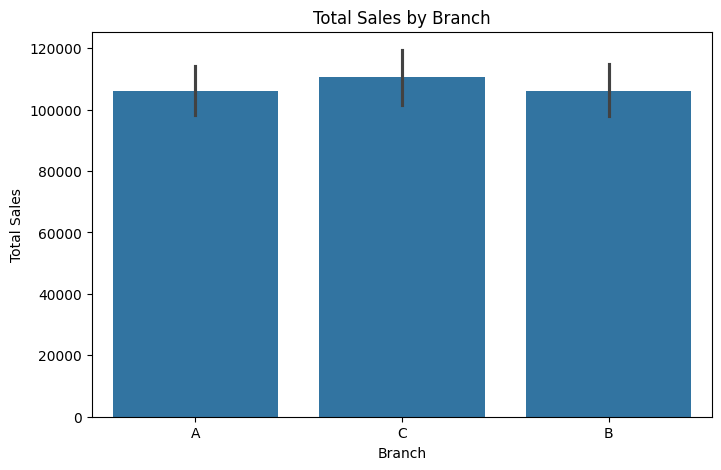

In [11]:
# ==========================================
# TOTAL SALES BY BRANCH
# ==========================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Branch",
    y="Total",
    estimator=sum
)

plt.title("Total Sales by Branch")
plt.xlabel("Branch")
plt.ylabel("Total Sales")

plt.show()


In [12]:
# ==========================================
# CITY-WISE SALES ANALYSIS
# ==========================================

city_sales = df.groupby("City")["Total"].sum().sort_values(ascending=False)

print("===== SALES BY CITY =====")
print(city_sales.round(2))

===== SALES BY CITY =====
City
Naypyitaw    110568.71
Yangon       106200.37
Mandalay     106197.67
Name: Total, dtype: float64


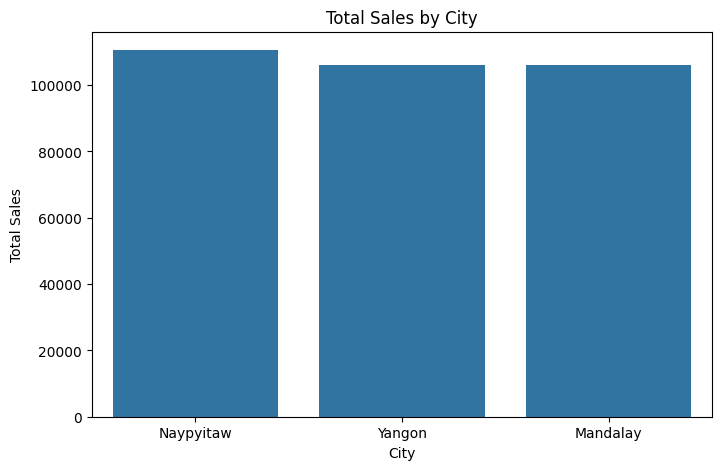

In [13]:
# ==========================================
# TOTAL SALES BY CITY
# ==========================================

plt.figure(figsize=(8, 5))

sns.barplot(
    x=city_sales.index,
    y=city_sales.values
)

plt.title("Total Sales by City")
plt.xlabel("City")
plt.ylabel("Total Sales")

plt.show()

In [14]:
# ==========================================
# PRODUCT LINE SALES ANALYSIS
# ==========================================

product_sales = df.groupby("Product line")["Total"].sum().sort_values(ascending=False)

print("===== SALES BY PRODUCT LINE =====")
print(product_sales.round(2))

===== SALES BY PRODUCT LINE =====
Product line
Food and beverages        56144.84
Sports and travel         55122.83
Electronic accessories    54337.53
Fashion accessories       54305.90
Home and lifestyle        53861.91
Health and beauty         49193.74
Name: Total, dtype: float64


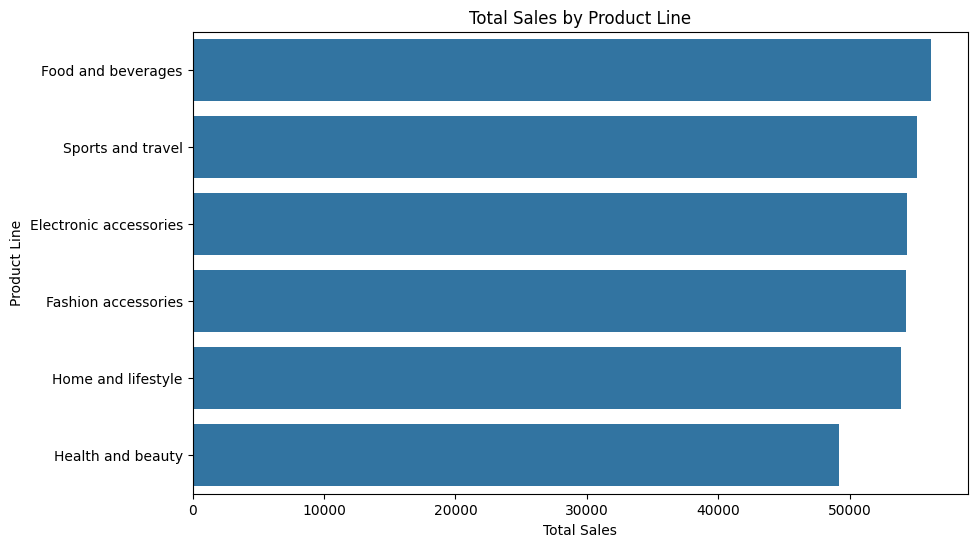

In [15]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=product_sales.values,
    y=product_sales.index
)

plt.title("Total Sales by Product Line")
plt.xlabel("Total Sales")
plt.ylabel("Product Line")

plt.show()

In [16]:
# ==========================================
# CUSTOMER TYPE SALES ANALYSIS
# ==========================================

customer_analysis = df.groupby("Customer type").agg(
    Transactions=("Invoice ID", "count"),
    Total_Sales=("Total", "sum"),
    Average_Sale=("Total", "mean"),
    Average_Rating=("Rating", "mean")
)

print("===== CUSTOMER TYPE ANALYSIS =====")
print(customer_analysis.round(2))

===== CUSTOMER TYPE ANALYSIS =====
               Transactions  Total_Sales  Average_Sale  Average_Rating
Customer type                                                         
Member                  501    164223.44        327.79            6.94
Normal                  499    158743.30        318.12            7.01


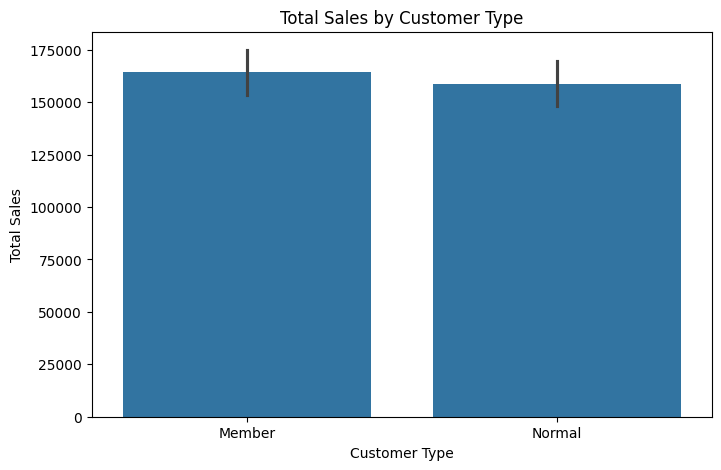

In [17]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Customer type",
    y="Total",
    estimator=sum
)

plt.title("Total Sales by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Total Sales")

plt.show()

In [18]:
# ==========================================
# GENDER-WISE SALES ANALYSIS
# ==========================================

gender_analysis = df.groupby("Gender").agg(
    Transactions=("Invoice ID", "count"),
    Total_Sales=("Total", "sum"),
    Average_Sale=("Total", "mean"),
    Average_Rating=("Rating", "mean")
)

print("===== GENDER-WISE SALES ANALYSIS =====")
print(gender_analysis.round(2))

===== GENDER-WISE SALES ANALYSIS =====
        Transactions  Total_Sales  Average_Sale  Average_Rating
Gender                                                         
Female           501    167882.92        335.10            6.96
Male             499    155083.82        310.79            6.98


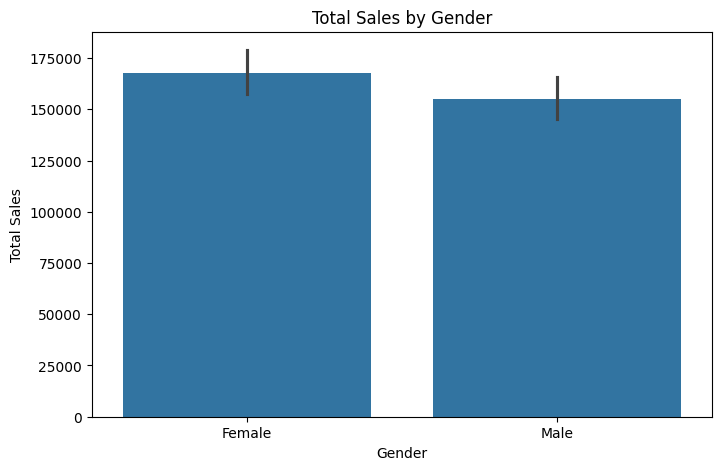

In [19]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Gender",
    y="Total",
    estimator=sum
)

plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")

plt.show()

In [20]:
# ==========================================
# PAYMENT METHOD SALES ANALYSIS
# ==========================================

payment_analysis = df.groupby("Payment").agg(
    Transactions=("Invoice ID", "count"),
    Total_Sales=("Total", "sum"),
    Average_Sale=("Total", "mean")
)

print("===== PAYMENT METHOD ANALYSIS =====")
print(payment_analysis.round(2))

===== PAYMENT METHOD ANALYSIS =====
             Transactions  Total_Sales  Average_Sale
Payment                                             
Cash                  344    112206.57        326.18
Credit card           311    100767.07        324.01
Ewallet               345    109993.11        318.82


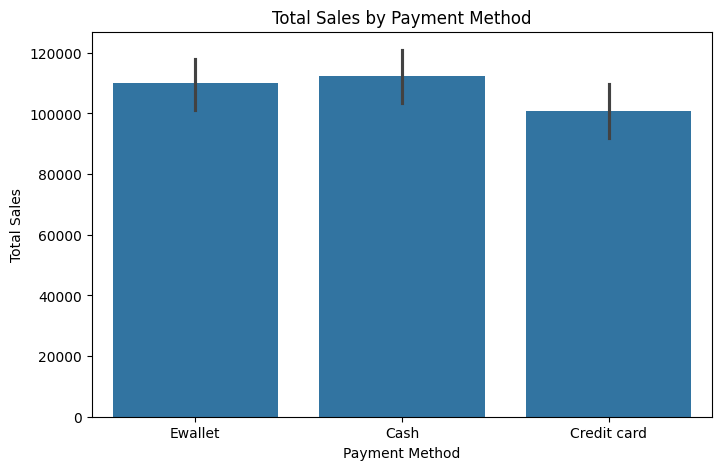

In [21]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Payment",
    y="Total",
    estimator=sum
)

plt.title("Total Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales")

plt.show()

In [22]:
# ==========================================
# MONTHLY SALES ANALYSIS
# ==========================================

monthly_sales = df.groupby("Month")["Total"].sum()

print("===== MONTHLY SALES =====")
print(monthly_sales.round(2))

===== MONTHLY SALES =====
Month
1    116291.87
2     97219.37
3    109455.51
Name: Total, dtype: float64


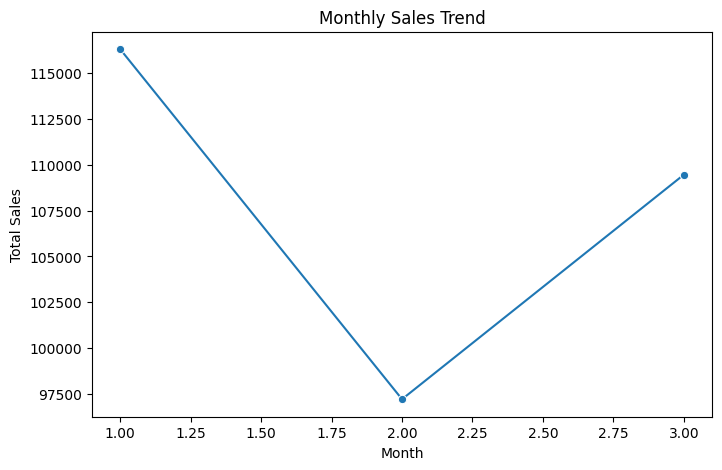

In [23]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.show()

In [24]:
# ==========================================
# MONTHLY GROSS INCOME ANALYSIS
# ==========================================

monthly_income = df.groupby("Month")["gross income"].sum()

print("===== MONTHLY GROSS INCOME =====")
print(monthly_income.round(2))

===== MONTHLY GROSS INCOME =====
Month
1    5537.71
2    4629.49
3    5212.17
Name: gross income, dtype: float64


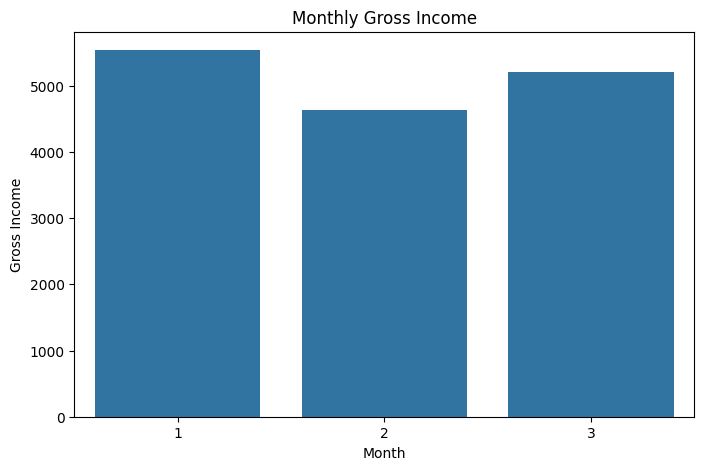

In [25]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=monthly_income.index,
    y=monthly_income.values
)

plt.title("Monthly Gross Income")
plt.xlabel("Month")
plt.ylabel("Gross Income")

plt.show()

In [26]:
# ==========================================
# PRODUCT LINE RATING ANALYSIS
# ==========================================

rating_product = df.groupby("Product line")["Rating"].mean().sort_values(ascending=False)

print("===== AVERAGE RATING BY PRODUCT LINE =====")
print(rating_product.round(2))

===== AVERAGE RATING BY PRODUCT LINE =====
Product line
Food and beverages        7.11
Fashion accessories       7.03
Health and beauty         7.00
Electronic accessories    6.92
Sports and travel         6.92
Home and lifestyle        6.84
Name: Rating, dtype: float64


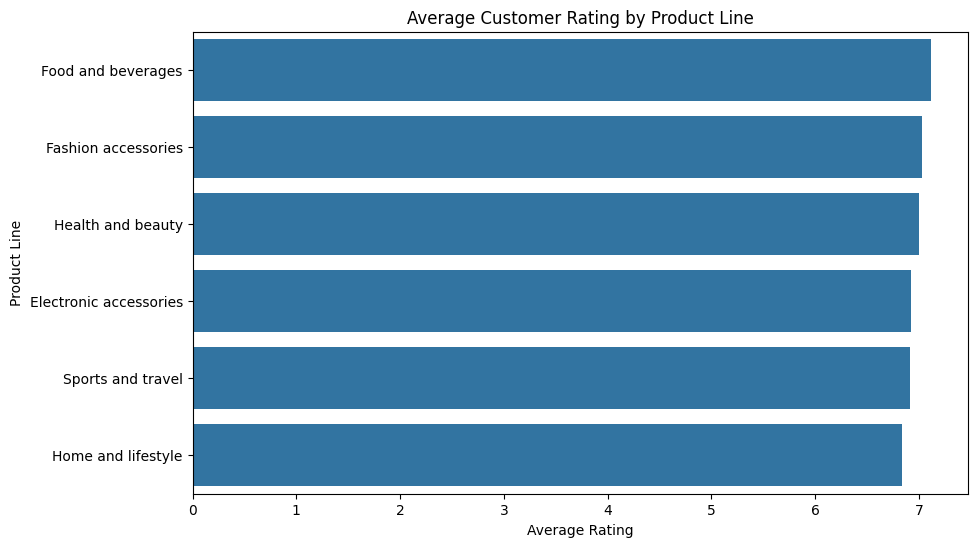

In [27]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=rating_product.values,
    y=rating_product.index
)

plt.title("Average Customer Rating by Product Line")
plt.xlabel("Average Rating")
plt.ylabel("Product Line")

plt.show()

In [28]:
# ==========================================
# CORRELATION ANALYSIS
# ==========================================

numeric_cols = df.select_dtypes(include=np.number)

correlation_matrix = numeric_cols.corr()

print("===== CORRELATION MATRIX =====")
print(correlation_matrix.round(2))

===== CORRELATION MATRIX =====
                         Unit price  Quantity  Tax 5%  Total  cogs  \
Unit price                     1.00      0.01    0.63   0.63  0.63   
Quantity                       0.01      1.00    0.71   0.71  0.71   
Tax 5%                         0.63      0.71    1.00   1.00  1.00   
Total                          0.63      0.71    1.00   1.00  1.00   
cogs                           0.63      0.71    1.00   1.00  1.00   
gross margin percentage         NaN       NaN     NaN    NaN   NaN   
gross income                   0.63      0.71    1.00   1.00  1.00   
Rating                        -0.01     -0.02   -0.04  -0.04 -0.04   
Year                            NaN       NaN     NaN    NaN   NaN   
Month                         -0.03     -0.01   -0.02  -0.02 -0.02   
Day                            0.06     -0.04   -0.00  -0.00 -0.00   

                         gross margin percentage  gross income  Rating  Year  \
Unit price                                   NaN

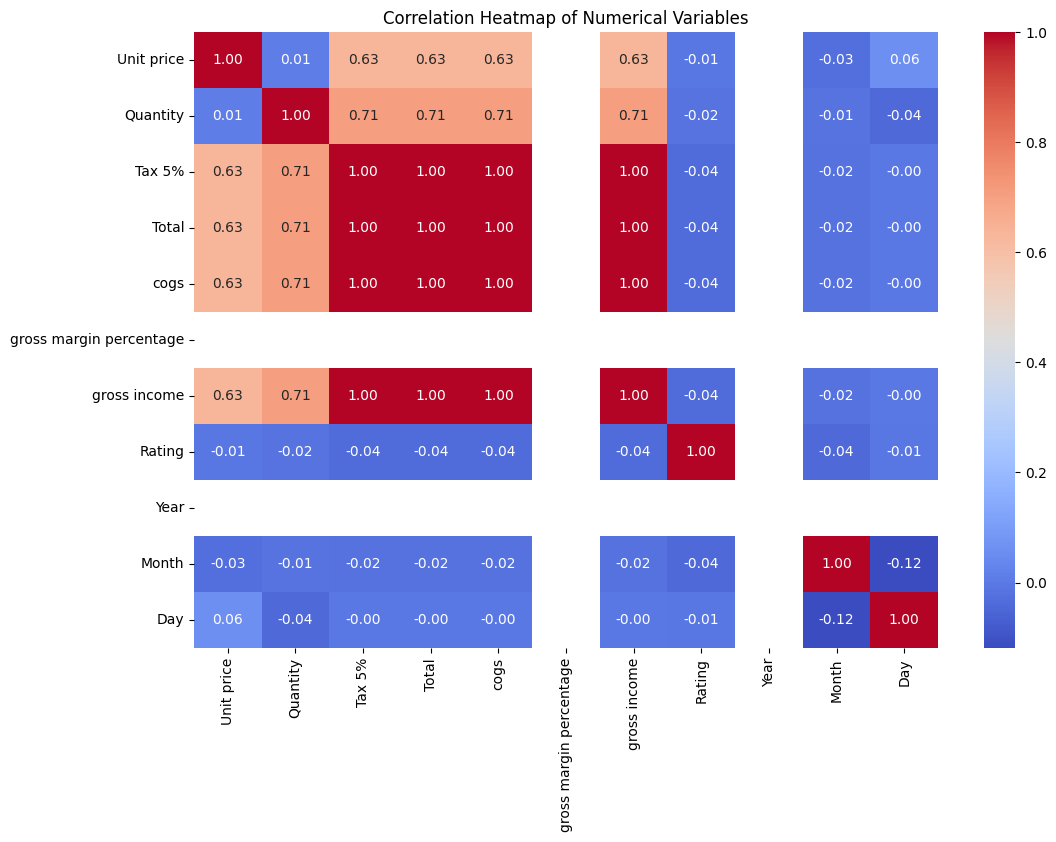

In [29]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Variables")

plt.show()

In [30]:
# ==========================================
# KEY INSIGHTS FROM SALES ANALYSIS
# ==========================================

top_product = product_sales.idxmax()
top_product_sales = product_sales.max()

top_city = city_sales.idxmax()
top_city_sales = city_sales.max()

top_customer = customer_analysis["Total_Sales"].idxmax()
top_customer_sales = customer_analysis["Total_Sales"].max()

top_payment = payment_analysis["Total_Sales"].idxmax()
top_payment_sales = payment_analysis["Total_Sales"].max()

best_rated_product = rating_product.idxmax()
best_rating = rating_product.max()

highest_month = monthly_sales.idxmax()
highest_month_sales = monthly_sales.max()

print("=" * 60)
print("                 KEY PROJECT INSIGHTS")
print("=" * 60)

print(f"1. Top Product Line       : {top_product}")
print(f"   Sales                  : ${top_product_sales:,.2f}")

print(f"\n2. Top City               : {top_city}")
print(f"   Sales                  : ${top_city_sales:,.2f}")

print(f"\n3. Highest-Selling Customer Type : {top_customer}")
print(f"   Sales                  : ${top_customer_sales:,.2f}")

print(f"\n4. Most Used/Highest Sales Payment : {top_payment}")
print(f"   Sales                  : ${top_payment_sales:,.2f}")

print(f"\n5. Highest Rated Product Line : {best_rated_product}")
print(f"   Average Rating           : {best_rating:.2f}")

print(f"\n6. Highest Sales Month     : Month {highest_month}")
print(f"   Sales                  : ${highest_month_sales:,.2f}")

print("=" * 60)

                 KEY PROJECT INSIGHTS
1. Top Product Line       : Food and beverages
   Sales                  : $56,144.84

2. Top City               : Naypyitaw
   Sales                  : $110,568.71

3. Highest-Selling Customer Type : Member
   Sales                  : $164,223.44

4. Most Used/Highest Sales Payment : Cash
   Sales                  : $112,206.57

5. Highest Rated Product Line : Food and beverages
   Average Rating           : 7.11

6. Highest Sales Month     : Month 1
   Sales                  : $116,291.87


In [31]:
# ==========================================
# FINAL PROJECT SUMMARY
# ==========================================

summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Transactions",
        "Total Quantity Sold",
        "Average Sale",
        "Average Rating",
        "Total Gross Income"
    ],
    "Value": [
        total_revenue,
        total_transactions,
        total_quantity,
        average_sale,
        average_rating,
        total_gross_income
    ]
})

print("===== FINAL PROJECT KPI SUMMARY =====")
print(summary)

===== FINAL PROJECT KPI SUMMARY =====
                   KPI          Value
0        Total Revenue  322966.749000
1   Total Transactions    1000.000000
2  Total Quantity Sold    5510.000000
3         Average Sale     322.966749
4       Average Rating       6.972700
5   Total Gross Income   15379.369000


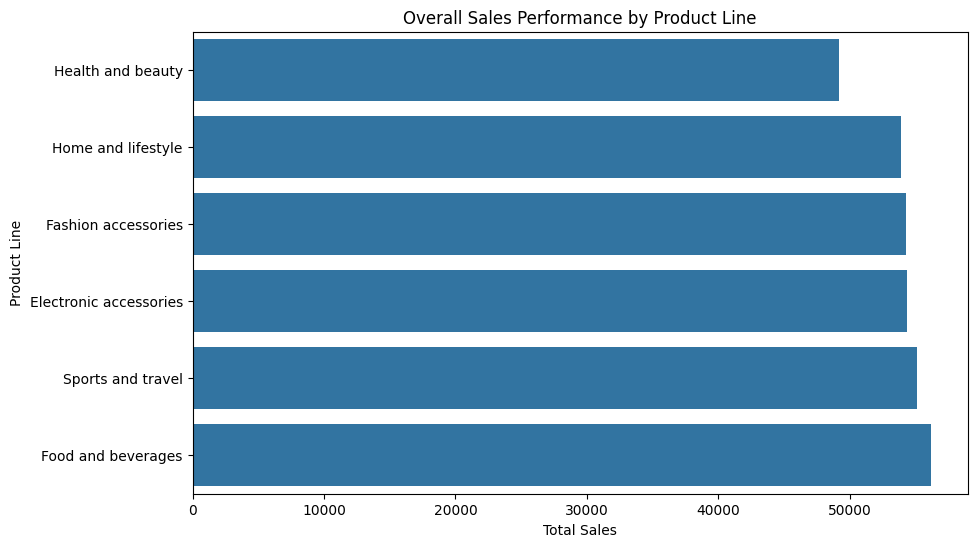

In [32]:
# ==========================================
# FINAL PROJECT VISUALIZATION
# ==========================================

plt.figure(figsize=(10, 6))

product_sales_sorted = product_sales.sort_values(ascending=True)

sns.barplot(
    x=product_sales_sorted.values,
    y=product_sales_sorted.index
)

plt.title("Overall Sales Performance by Product Line")
plt.xlabel("Total Sales")
plt.ylabel("Product Line")

plt.show()

In [33]:
# ==========================================
# FINAL PROJECT CONCLUSION
# ==========================================

print("=" * 65)
print("              SUPERMARKET SALES ANALYTICS")
print("                    FINAL CONCLUSION")
print("=" * 65)

print(f"Total Revenue              : ${total_revenue:,.2f}")
print(f"Total Transactions         : {total_transactions:,}")
print(f"Total Quantity Sold        : {total_quantity:,}")
print(f"Average Transaction Value  : ${average_sale:,.2f}")
print(f"Average Customer Rating    : {average_rating:.2f} / 10")
print(f"Total Gross Income         : ${total_gross_income:,.2f}")

print("\n--- Key Findings ---")

print(f"Highest Sales Product Line : {top_product}")
print(f"Highest Sales City         : {top_city}")
print(f"Highest Sales Customer Type: {top_customer}")
print(f"Highest Sales Payment Type : {top_payment}")
print(f"Highest Rated Product Line : {best_rated_product}")
print(f"Highest Sales Month        : Month {highest_month}")

print("=" * 65)
print("Project analysis completed successfully!")
print("=" * 65)

              SUPERMARKET SALES ANALYTICS
                    FINAL CONCLUSION
Total Revenue              : $322,966.75
Total Transactions         : 1,000
Total Quantity Sold        : 5,510
Average Transaction Value  : $322.97
Average Customer Rating    : 6.97 / 10
Total Gross Income         : $15,379.37

--- Key Findings ---
Highest Sales Product Line : Food and beverages
Highest Sales City         : Naypyitaw
Highest Sales Customer Type: Member
Highest Sales Payment Type : Cash
Highest Rated Product Line : Food and beverages
Highest Sales Month        : Month 1
Project analysis completed successfully!
